# 🧪 Ionic Liquid Viscosity Prediction

**Predicting the viscosity of ionic liquids from molecular structure and temperature, using RDKit descriptors and gradient-boosted tree ensembles.**

![Python](https://img.shields.io/badge/Python-3.12-blue) ![RDKit](https://img.shields.io/badge/RDKit-cheminformatics-green) ![XGBoost](https://img.shields.io/badge/XGBoost-%7C%20CatBoost%20%7C%20RF-orange) ![scikit-learn](https://img.shields.io/badge/scikit--learn-GroupKFold-yellow)

---

## 📌 Overview

Each row of the dataset is an **ionic liquid** (a cation + anion pair) measured at a given **temperature `T`** (K), with its measured **viscosity** (`Viscosity_Pa_s`) as the regression target. A separate `smiles.csv` maps every ion name to its SMILES string.

The goal is to predict viscosity for unseen conditions in `test.csv`. The approach:

1. Convert each ion's SMILES into physicochemical descriptors with **RDKit**.
2. Engineer cation-anion **interaction features** and **temperature-coupled features** (`1/T`).
3. Benchmark **Random Forest**, **XGBoost** and **CatBoost** with **GroupKFold** cross-validation, grouped by ion pair so that no pair appears in both train and validation folds.
4. Blend the three models into the final submission.

Final prediction = `0.35 × CatBoost + 0.35 × XGBoost + 0.30 × Random Forest`.

## 🗂️ Notebook Contents

1. [Setup](#1.-Setup)
2. [Data Loading](#2.-Data-Loading)
3. [Exploratory Data Analysis & Cleaning](#3.-Exploratory-Data-Analysis-&-Cleaning)
4. [Merging SMILES with Training Data](#4.-Merging-SMILES-with-Training-Data)
5. [Feature Engineering](#5.-Feature-Engineering)
6. [Model Benchmarking with GroupKFold](#6.-Model-Benchmarking-with-GroupKFold)
7. [Preparing the Test Set](#7.-Preparing-the-Test-Set)
8. [Final Predictions & Submission](#8.-Final-Predictions-&-Submission)

---
## 1. Setup

Install dependencies and import the libraries used throughout the notebook.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_validate, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, rdMolDescriptors, Crippen

---
## 2. Data Loading

Three files are used:

- **`smiles.csv`**: maps each `Cation` / `Anion` name to its SMILES string (`Cat_sm`, `An_sm`)
- **`train.csv`**: labelled measurements (`Cation`, `Anion`, `T`, `Viscosity_Pa_s`)
- **`test.csv`**: unlabelled conditions to predict (`ID`, `Cation`, `Anion`, `T`)

In [2]:
smiles = pd.read_csv('data/smiles.csv')
smiles.head()

,Cation,Cat_sm,Anion,An_sm
0,1-(2-methoxyethyl)-1-methylazepan-1-ium,COCC[N+]1(C)CCCCCC1,bis(trifluoromethylsulfonyl)azanide,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F
1,1-(2-methoxyethyl)-1-methylazepan-1-ium,COCC[N+]1(C)CCCCCC1,trifluoromethanesulfonate,O=S(=O)([O-])C(F)(F)F
2,1-(2-methoxyethyl)-1-methylazepan-1-ium,COCC[N+]1(C)CCCCCC1,trifluoroacetate,O=C([O-])C(F)(F)F
3,"1,1-bis(2-methoxyethyl)azepan-1-ium",COCC[N+]1(CCOC)CCCCCC1,bis(trifluoromethylsulfonyl)azanide,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F
4,1-butyl-1-methylazepan-1-ium,CCCC[N+]1(C)CCCCCC1,bis(trifluoromethylsulfonyl)azanide,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F


In [3]:
train = pd.read_csv('data/train.csv')
train.head()

,Cation,Anion,T,Viscosity_Pa_s
0,1-butyl-3-methylimidazolium,iodide,388.15,-4.334380
1,1-butyl-1-methylpyrrolidin-1-ium,tetracyanoboranuide,298.20,-3.037305
2,3-methyl-1-octyl-1H-imidazol-3-ium,pyrrolidine-2-carboxylate,313.15,-0.913295
3,4-heptyl-4-methylmorpholinium,N-cyanocyanamide,348.00,-3.134994
4,tetrabutylphosphonium,3-(cyclohexylamino)-2-hydroxypropanesulfonate,328.15,-0.248461


In [4]:
test = pd.read_csv('data/test.csv')
test.head()

,ID,Cation,Anion,T
0,1,1-ethyl-1-(3-hydroxypropyl)piperidin-1-ium,bis(trifluoromethylsulfonyl)azanide,333.15
1,2,hexyl(tributyl)phosphanium,bis(trifluoromethylsulfonyl)azanide,348.15
2,3,triethyl(heptyl)phosphanium,4-nitro-1H-pyrazol-1-ide,323.15
3,4,1-butyl-1-methylpyrrolidinium,phenyltrifluoroborate,313.00
4,5,3-methyl-1-octylpyridin-1-ium,tetrafluoroborate,298.15


---
## 3. Exploratory Data Analysis & Cleaning

Summary statistics reveal **non-physical values** in the training data: the minimum temperature is below 0 K (impossible on the Kelvin scale) and the minimum target value is an extreme outlier (≈ −100) compared with the rest of the distribution (mean ≈ −2.7, std ≈ 2.4).

In [5]:
train.describe()

,T,Viscosity_Pa_s
count,11705.000000,11705.000000
mean,320.463333,-2.700589
std,25.627545,2.360434
min,-148.056483,-100.254865
25%,303.150000,-3.803169
50%,318.150000,-2.811745
75%,338.150000,-1.666008
max,573.000000,5.236442


### 3.1 Visual outlier & validity checks

`describe()` only gives numbers; plots make bad values obvious. Histograms show the shape, boxplots flag points beyond 1.5 × IQR, and the scatter of target vs. temperature highlights physically invalid rows (temperature ≤ 0 K) in red.

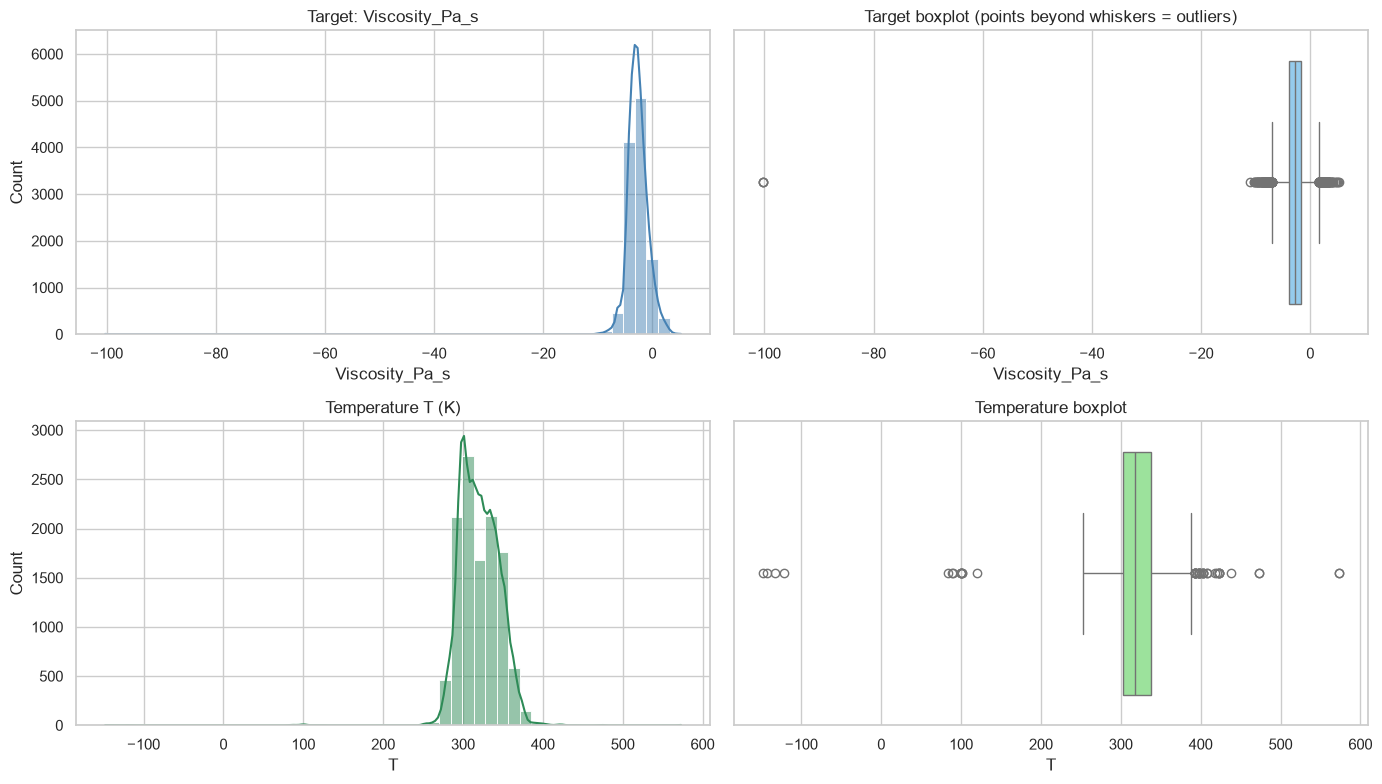

In [6]:
sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(train['Viscosity_Pa_s'], bins=50, kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Target: Viscosity_Pa_s')

sns.boxplot(x=train['Viscosity_Pa_s'], ax=axes[0, 1], color='lightskyblue')
axes[0, 1].set_title('Target boxplot (points beyond whiskers = outliers)')

sns.histplot(train['T'], bins=50, kde=True, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Temperature T (K)')

sns.boxplot(x=train['T'], ax=axes[1, 1], color='lightgreen')
axes[1, 1].set_title('Temperature boxplot')

plt.tight_layout()
plt.show()

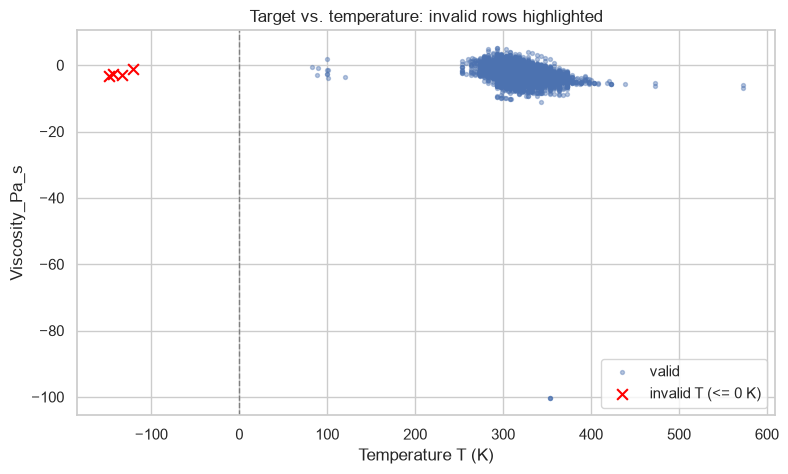

In [7]:
invalid_T = train['T'] <= 0   # impossible on the Kelvin scale

plt.figure(figsize=(9, 5))
plt.scatter(train.loc[~invalid_T, 'T'], train.loc[~invalid_T, 'Viscosity_Pa_s'],
            s=8, alpha=0.4, label='valid')
plt.scatter(train.loc[invalid_T, 'T'], train.loc[invalid_T, 'Viscosity_Pa_s'],
            s=60, color='red', marker='x', label='invalid T (<= 0 K)')
plt.axvline(0, color='grey', ls='--', lw=1)
plt.xlabel('Temperature T (K)')
plt.ylabel('Viscosity_Pa_s')
plt.title('Target vs. temperature: invalid rows highlighted')
plt.legend()
plt.show()

In [8]:
# Quantify what the plots show
q1, q3 = train['Viscosity_Pa_s'].quantile([0.25, 0.75])
iqr = q3 - q1
visc_outlier = (train['Viscosity_Pa_s'] < q1 - 1.5 * iqr) | (train['Viscosity_Pa_s'] > q3 + 1.5 * iqr)

print("Missing values per column:")
print(train.isna().sum().to_string())
print(f"\nDuplicate rows            : {train.duplicated().sum()}")
print(f"Temperature <= 0 K        : {invalid_T.sum()}")
print(f"Target outliers (1.5xIQR) : {visc_outlier.sum()}")
print(f"Extreme target (< -20)    : {(train['Viscosity_Pa_s'] < -20).sum()}")

Missing values per column:
Cation            0
Anion             0
T                 0
Viscosity_Pa_s    0

Duplicate rows            : 102
Temperature <= 0 K        : 4
Target outliers (1.5xIQR) : 336
Extreme target (< -20)    : 3


Rows with non-positive temperatures (invalid in Kelvin, and `1/T` would be undefined or negative) are removed. The plot below re-checks the data after cleaning.

In [9]:
# Remove physically impossible temperatures (T <= 0 K)
train = train[train['T'] > 0].copy()

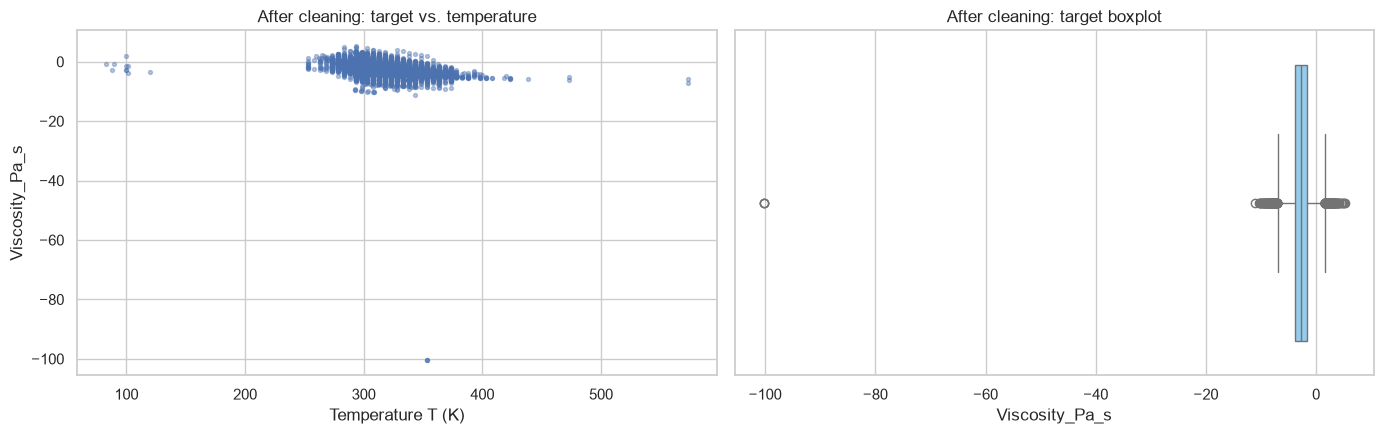

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(train['T'], train['Viscosity_Pa_s'], s=8, alpha=0.4)
axes[0].set_xlabel('Temperature T (K)'); axes[0].set_ylabel('Viscosity_Pa_s')
axes[0].set_title('After cleaning: target vs. temperature')

sns.boxplot(x=train['Viscosity_Pa_s'], ax=axes[1], color='lightskyblue')
axes[1].set_title('After cleaning: target boxplot')

plt.tight_layout()
plt.show()

### 3.2 Ion composition

How many distinct cations / anions are there, which ones dominate, and how many measurements does each ion pair have? Heavily imbalanced ions mean the model sees some chemistries far more often than others.

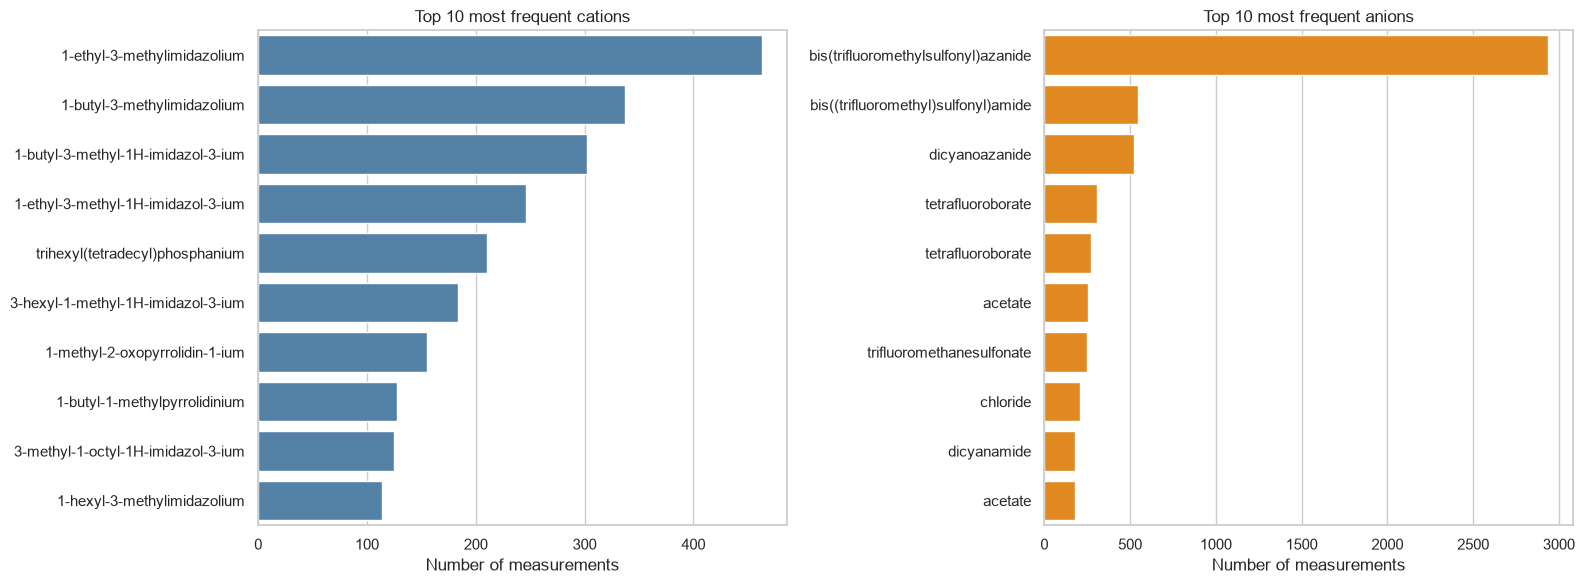

Unique cations : 831
Unique anions  : 260


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_cations = train['Cation'].value_counts().head(10)
sns.barplot(y=top_cations.index, x=top_cations.values, ax=axes[0], color='steelblue')
axes[0].set_title('Top 10 most frequent cations')
axes[0].set_xlabel('Number of measurements')
axes[0].set_ylabel('')

top_anions = train['Anion'].value_counts().head(10)
sns.barplot(y=top_anions.index, x=top_anions.values, ax=axes[1], color='darkorange')
axes[1].set_title('Top 10 most frequent anions')
axes[1].set_xlabel('Number of measurements')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print(f"Unique cations : {train['Cation'].nunique()}")
print(f"Unique anions  : {train['Anion'].nunique()}")

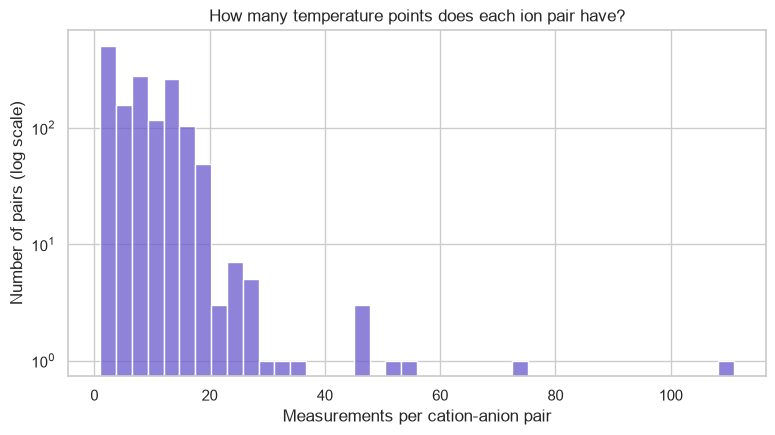

Unique ion pairs: 1505
count    1505.0
mean        7.8
std         6.9
min         1.0
25%         1.0
50%         8.0
75%        12.0
max       111.0


In [12]:
pair_counts = train.groupby(['Cation', 'Anion']).size()

plt.figure(figsize=(9, 4.5))
sns.histplot(pair_counts, bins=40, color='slateblue')
plt.yscale('log')
plt.xlabel('Measurements per cation-anion pair')
plt.ylabel('Number of pairs (log scale)')
plt.title('How many temperature points does each ion pair have?')
plt.show()

print(f"Unique ion pairs: {len(pair_counts)}")
print(pair_counts.describe().round(1).to_string())

### 3.3 Train vs. test distribution shift

If the test set contains ions or temperatures the model never saw during training, validation must mimic that. These plots compare the two sets, which is the motivation for using `GroupKFold` by ion pair.

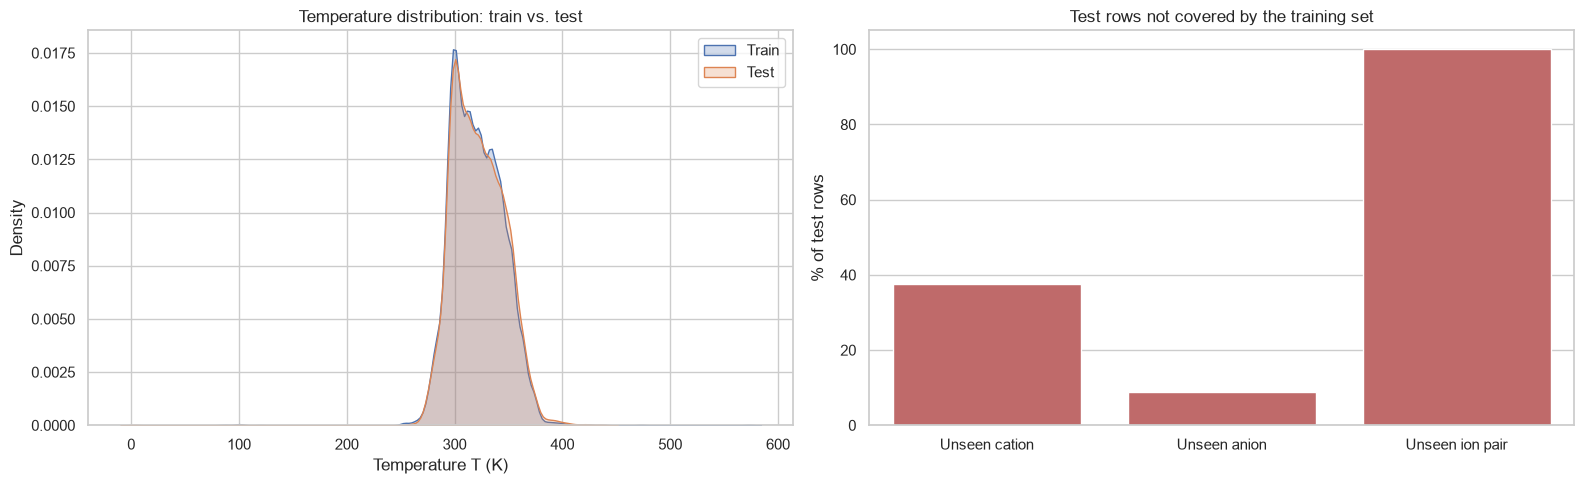

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Temperature distribution
sns.kdeplot(train['T'], label='Train', fill=True, ax=axes[0])
sns.kdeplot(test['T'], label='Test', fill=True, ax=axes[0])
axes[0].set_title('Temperature distribution: train vs. test')
axes[0].set_xlabel('Temperature T (K)')
axes[0].legend()

# Share of test rows whose ions / pair never appear in train
train_pairs = set(zip(train['Cation'], train['Anion']))
unseen = {
    'Unseen cation': (~test['Cation'].isin(train['Cation'])).mean(),
    'Unseen anion': (~test['Anion'].isin(train['Anion'])).mean(),
    'Unseen ion pair': pd.Series([p not in train_pairs for p in zip(test['Cation'], test['Anion'])]).mean(),
}
sns.barplot(x=list(unseen.keys()), y=[v * 100 for v in unseen.values()], ax=axes[1], color='indianred')
axes[1].set_ylabel('% of test rows')
axes[1].set_title('Test rows not covered by the training set')

plt.tight_layout()
plt.show()

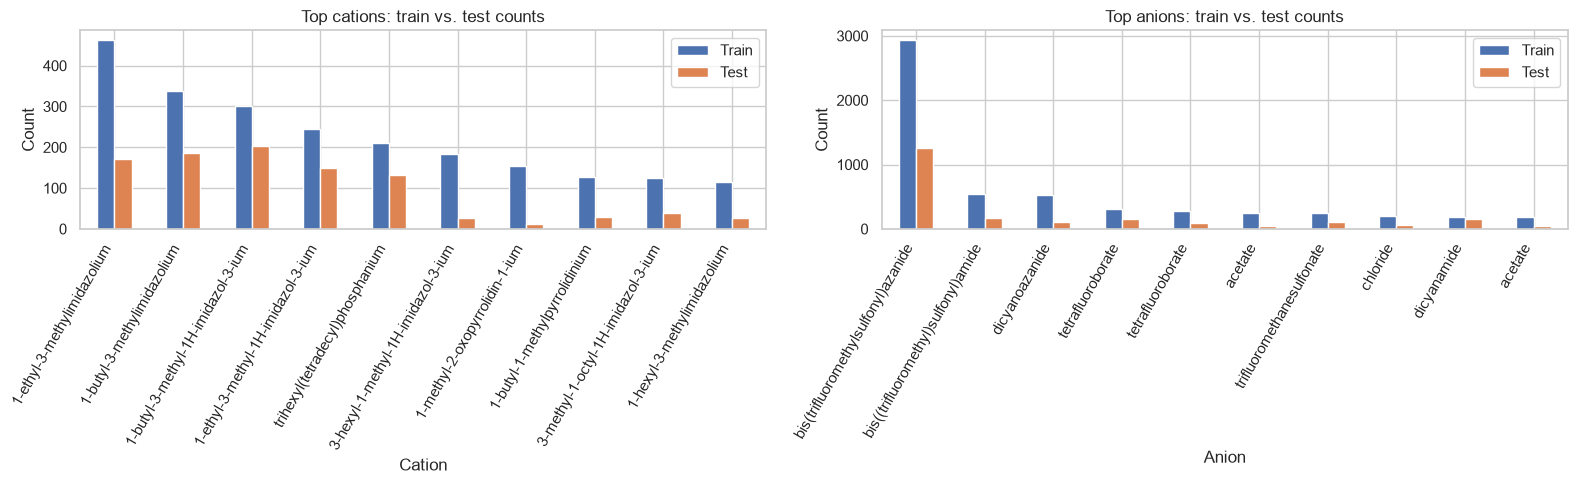

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, col in zip(axes, ['Cation', 'Anion']):
    top = train[col].value_counts().head(10).index
    comp = pd.DataFrame({
        'Train': train[col].value_counts().reindex(top, fill_value=0),
        'Test': test[col].value_counts().reindex(top, fill_value=0),
    })
    comp.plot(kind='bar', ax=ax)
    ax.set_title(f'Top {col.lower()}s: train vs. test counts')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=60)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')

plt.tight_layout()
plt.show()

---
## 4. Merging SMILES with Training Data

Attach the SMILES string of each cation and anion to the training rows.

In [15]:
train = train.merge(smiles, how='left', on=['Cation', 'Anion'])
train

,Cation,Anion,T,Viscosity_Pa_s,Cat_sm,An_sm
0,1-butyl-3-methylimidazolium,iodide,388.15,-4.334380,CCCC[n+]1ccn(C)c1,[I-]
1,1-butyl-1-methylpyrrolidin-1-ium,tetracyanoboranuide,298.20,-3.037305,CCCC[N+]1(C)CCCC1,N#C[B-](C#N)(C#N)C#N
2,3-methyl-1-octyl-1H-imidazol-3-ium,pyrrolidine-2-carboxylate,313.15,-0.913295,CCCCCCCCn1cc[n+](C)c1,O=C([O-])C1CCCN1
3,4-heptyl-4-methylmorpholinium,N-cyanocyanamide,348.00,-3.134994,CCCCCCC[N+]1(C)CCOCC1,N#CNC#N
4,tetrabutylphosphonium,3-(cyclohexylamino)-2-hydroxypropanesulfonate,328.15,-0.248461,CCCC[P+](CCCC)(CCCC)CCCC,O=S(=O)([O-])CC(O)CNC1CCCCC1
...,...,...,...,...,...,...
11696,methyltrioctylammonium,4-ethyloctanoate,358.15,-2.385967,CCCCCCCC[N+](C)(CCCCCCCC)CCCCCCCC,CCCCC(CC)CCC(=O)[O-]
11697,1-(2-methoxyethyl)-1-methylpiperidin-1-ium,trifluoroacetate,308.10,-1.845160,COCC[N+]1(C)CCCCC1,O=C([O-])C(F)(F)F
11698,"1,1-bis[2-(2-methoxyethoxy)ethyl]piperidin-1-ium",bis(trifluoromethylsulfonyl)azanide,335.85,-3.694495,COCCOCC[N+]1(CCOCCOC)CCCCC1,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F
11699,2-(ethoxymethyl)-3-ethyl-1-methyl-1H-imidazol-...,bis(trifluoromethylsulfonyl)azanide,353.20,-4.771815,CCOCc1n(C)cc[n+]1CC,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F


Some ions have **no SMILES mapping** (e.g. `tris(dihexylamino)cycloprop-2-en-1-ylium`). Descriptors cannot be computed for them, so these rows are dropped. The inverse temperature `1/T` is also added here.

> **Why `1/T`?** Viscosity of liquids typically follows an Arrhenius-like dependence on inverse temperature, so `1/T` is a physically motivated feature.

In [16]:
train[train['Cat_sm'].isna()]

,Cation,Anion,T,Viscosity_Pa_s,Cat_sm,An_sm
891,tris(dihexylamino)cycloprop-2-en-1-ylium,bis(trifluoromethylsulfonyl)azanide,353.15,-100.254865,NaN,NaN
4981,tris(dihexylamino)cycloprop-2-en-1-ylium,bis(trifluoromethylsulfonyl)azanide,353.15,-100.254865,NaN,NaN
10026,tris(dihexylamino)cycloprop-2-en-1-ylium,bis(trifluoromethylsulfonyl)azanide,353.15,-100.254865,NaN,NaN


In [17]:
train = train.dropna(subset=['Cat_sm', 'An_sm'])
train['inv_T'] = 1 / train['T']

---
## 5. Feature Engineering

### 5.1 Per-ion molecular descriptors

For every cation and anion, 15 descriptors are computed from its SMILES with RDKit:

| Group | Descriptors |
|---|---|
| Size & shape | molecular weight, heavy-atom count, rotatable bonds, aromatic rings, fraction of sp³ carbons, **longest alkyl chain** |
| Polarity & H-bonding | TPSA, H-bond donors, H-bond acceptors, formal charge |
| Composition | counts of F, N, O, S atoms |
| Lipophilicity | Crippen LogP (hydrophobicity) |

The longest alkyl chain is a custom feature: a depth-first search over non-ring, non-aromatic carbon atoms.

In [18]:
def get_max_alkyl_length(mol):
    """Length of the longest chain of connected non-ring, non-aromatic carbons."""
    if mol is None:
        return 0

    # Candidate atoms: aliphatic carbons that are not part of a ring
    valid_atoms = {
        atom.GetIdx() for atom in mol.GetAtoms()
        if atom.GetAtomicNum() == 6 and not atom.IsInRing() and not atom.GetIsAromatic()
    }
    if not valid_atoms:
        return 0

    max_len = 0

    def dfs(current_atom, current_path):
        nonlocal max_len
        max_len = max(max_len, len(current_path))
        atom = mol.GetAtomWithIdx(current_atom)
        for neighbor in atom.GetNeighbors():
            n_idx = neighbor.GetIdx()
            if n_idx in valid_atoms and n_idx not in current_path:
                dfs(n_idx, current_path + [n_idx])

    for atom_idx in valid_atoms:
        dfs(atom_idx, [atom_idx])
    return max_len


def description(smi):
    """Compute RDKit descriptors for a single SMILES string."""
    mol = Chem.MolFromSmiles(smi)
    dic = {}
    dic["MW"] = Descriptors.MolWt(mol)
    dic["NumHDonors"] = Descriptors.NumHDonors(mol)
    dic["NumHAcceptors"] = Descriptors.NumHAcceptors(mol)
    dic["Tpsa"] = Descriptors.TPSA(mol)
    dic["NumRotatableBonds"] = Descriptors.NumRotatableBonds(mol)
    dic["Aromaticrings"] = rdMolDescriptors.CalcNumAromaticRings(mol)
    dic["HeavyAtoms"] = mol.GetNumHeavyAtoms()
    dic["F_count"] = sum(1 for a in mol.GetAtoms() if a.GetSymbol() == "F")
    dic["N_count"] = sum(1 for a in mol.GetAtoms() if a.GetSymbol() == "N")
    dic["O_count"] = sum(1 for a in mol.GetAtoms() if a.GetSymbol() == "O")
    dic["S_count"] = sum(1 for a in mol.GetAtoms() if a.GetSymbol() == "S")
    dic["Charge"] = Chem.GetFormalCharge(mol)
    dic["Hydrophobicity"] = Crippen.MolLogP(mol)
    dic["saturation"] = rdMolDescriptors.CalcFractionCSP3(mol)
    dic["Max_Alkyl_Length"] = get_max_alkyl_length(mol)
    return dic


def add_ion_features(df):
    """Append `Cat_*` and `An_*` descriptor columns to a dataframe with `Cat_sm` / `An_sm`."""
    cation = df["Cat_sm"].apply(description).apply(pd.Series).add_prefix("Cat_")
    anion = df["An_sm"].apply(description).apply(pd.Series).add_prefix("An_")
    return pd.concat([df, cation, anion], axis=1)

In [19]:
train = add_ion_features(train)
train

,Cation,Anion,T,Viscosity_Pa_s,Cat_sm,An_sm,inv_T,Cat_MW,Cat_NumHDonors,Cat_NumHAcceptors,...,An_Aromaticrings,An_HeavyAtoms,An_F_count,An_N_count,An_O_count,An_S_count,An_Charge,An_Hydrophobicity,An_saturation,An_Max_Alkyl_Length
0,1-butyl-3-methylimidazolium,iodide,388.15,-4.334380,CCCC[n+]1ccn(C)c1,[I-],0.002576,139.222,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,-1.0,-2.99600,0.0,0.0
1,1-butyl-1-methylpyrrolidin-1-ium,tetracyanoboranuide,298.20,-3.037305,CCCC[N+]1(C)CCCC1,N#C[B-](C#N)(C#N)C#N,0.003353,142.266,0.0,0.0,...,0.0,9.0,0.0,4.0,0.0,0.0,-1.0,-0.31368,0.0,1.0
2,3-methyl-1-octyl-1H-imidazol-3-ium,pyrrolidine-2-carboxylate,313.15,-0.913295,CCCCCCCCn1cc[n+](C)c1,O=C([O-])C1CCCN1,0.003193,195.330,0.0,0.0,...,0.0,8.0,0.0,1.0,2.0,0.0,-1.0,-1.51170,0.8,1.0
3,4-heptyl-4-methylmorpholinium,N-cyanocyanamide,348.00,-3.134994,CCCCCCC[N+]1(C)CCOCC1,N#CNC#N,0.002874,200.346,0.0,1.0,...,0.0,5.0,0.0,3.0,0.0,0.0,0.0,-0.46184,0.0,1.0
4,tetrabutylphosphonium,3-(cyclohexylamino)-2-hydroxypropanesulfonate,328.15,-0.248461,CCCC[P+](CCCC)(CCCC)CCCC,O=S(=O)([O-])CC(O)CNC1CCCCC1,0.003047,259.438,0.0,0.0,...,0.0,15.0,0.0,1.0,4.0,1.0,-1.0,-0.18520,1.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11696,methyltrioctylammonium,4-ethyloctanoate,358.15,-2.385967,CCCCCCCC[N+](C)(CCCCCCCC)CCCCCCCC,CCCCC(CC)CCC(=O)[O-],0.002792,368.714,0.0,0.0,...,0.0,12.0,0.0,0.0,2.0,0.0,-1.0,1.73290,0.9,8.0
11697,1-(2-methoxyethyl)-1-methylpiperidin-1-ium,trifluoroacetate,308.10,-1.845160,COCC[N+]1(C)CCCCC1,O=C([O-])C(F)(F)F,0.003246,158.265,0.0,1.0,...,0.0,7.0,3.0,0.0,2.0,0.0,-1.0,-0.70140,0.5,2.0
11698,"1,1-bis[2-(2-methoxyethoxy)ethyl]piperidin-1-ium",bis(trifluoromethylsulfonyl)azanide,335.85,-3.694495,COCCOCC[N+]1(CCOCCOC)CCCCC1,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F,0.002978,290.424,0.0,4.0,...,0.0,15.0,6.0,1.0,4.0,2.0,-1.0,1.05930,1.0,1.0
11699,2-(ethoxymethyl)-3-ethyl-1-methyl-1H-imidazol-...,bis(trifluoromethylsulfonyl)azanide,353.20,-4.771815,CCOCc1n(C)cc[n+]1CC,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F,0.002831,169.248,0.0,1.0,...,0.0,15.0,6.0,1.0,4.0,2.0,-1.0,1.05930,1.0,1.0


### 5.2 Interaction features

Ionic liquid viscosity depends on how the cation and anion interact, and on how that interaction changes with temperature. The following combined features are added:

| Feature | Meaning |
|---|---|
| `Total_MW`, `Tpsa_sum`, `total_F` | Summed size / polarity / fluorine content of the ion pair |
| `MW_diff` | Mass asymmetry between cation and anion |
| `hb_interact` | Cation H-bond donors × anion H-bond acceptors |
| `charge_interaction` | Cation charge × anion charge |
| `invT_MW`, `invT_charge`, `invT_Tpsa` | Temperature-coupled terms (`1/T` × feature) |

In [20]:
def add_interaction_features(df):
    """Add cation-anion interaction and temperature-coupled features (in place)."""
    df["Total_MW"] = df["Cat_MW"] + df["An_MW"]
    df["total_F"] = df["Cat_F_count"] + df["An_F_count"]
    df["hb_interact"] = df["Cat_NumHDonors"] * df["An_NumHAcceptors"]
    df["charge_interaction"] = df["Cat_Charge"] * df["An_Charge"]
    df["Tpsa_sum"] = df["Cat_Tpsa"] + df["An_Tpsa"]
    df["MW_diff"] = abs(df["Cat_MW"] - df["An_MW"])
    df["invT_MW"] = df["inv_T"] * df["Total_MW"]
    df["invT_charge"] = df["inv_T"] * df["charge_interaction"]
    df["invT_Tpsa"] = df["inv_T"] * df["Tpsa_sum"]
    return df


train = add_interaction_features(train)

### 5.3 Feature analysis

With features built, we check how they relate to the target. Correlations are linear and only a first look (tree models can use non-linear relationships), but they show which descriptors carry signal and which are redundant.

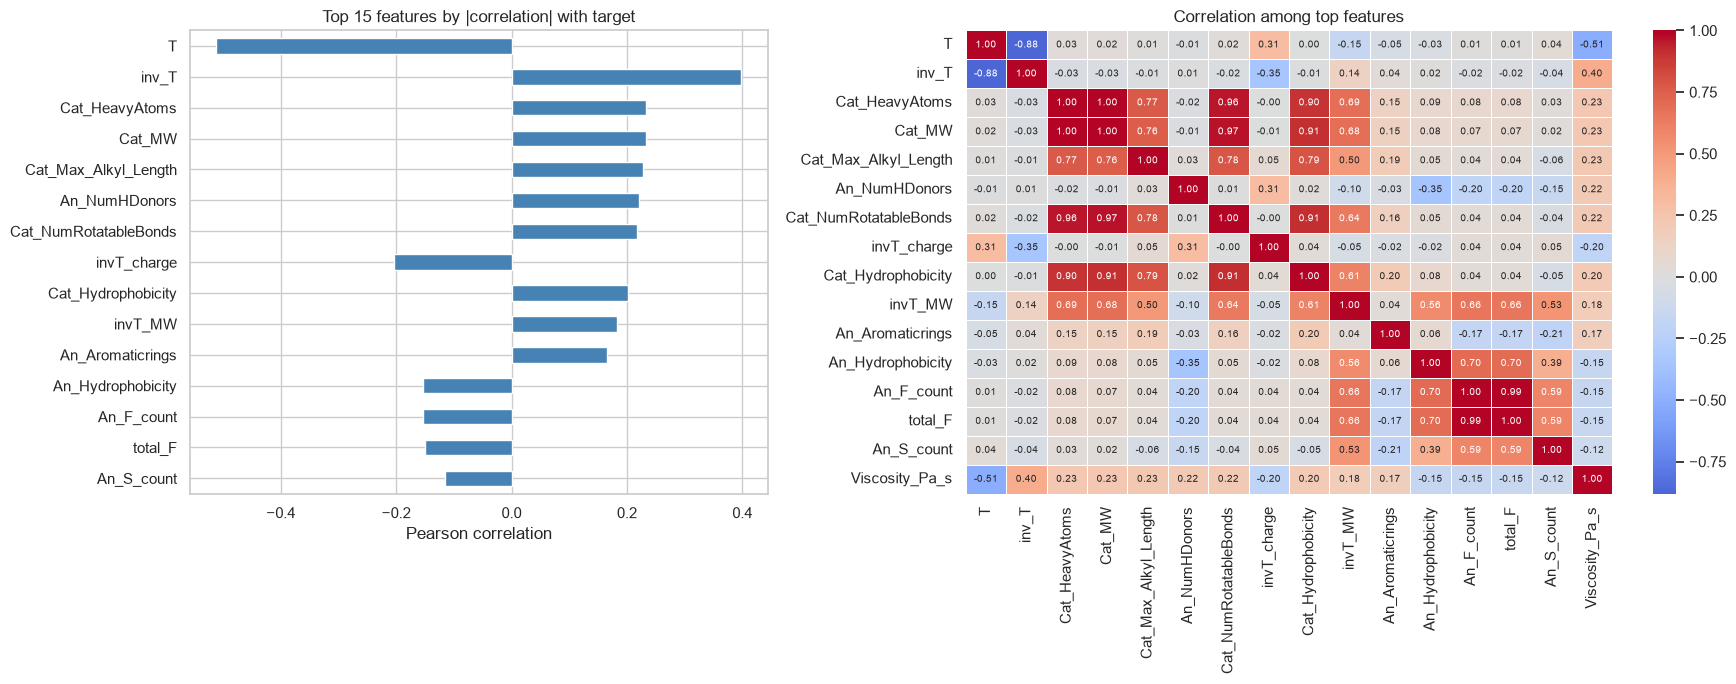

In [21]:
num = train.loc[:, ~train.columns.duplicated()].select_dtypes('number')
corr_target = num.corr()['Viscosity_Pa_s'].drop('Viscosity_Pa_s')
top_feats = corr_target.abs().sort_values(ascending=False).head(15).index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 1.4]})

corr_target[top_feats][::-1].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top 15 features by |correlation| with target')
axes[0].set_xlabel('Pearson correlation')

sns.heatmap(num[top_feats + ['Viscosity_Pa_s']].corr(), cmap='coolwarm', center=0,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.4, ax=axes[1])
axes[1].set_title('Correlation among top features')

plt.tight_layout()
plt.show()

### 5.4 Viscosity vs. inverse temperature

For a fixed ion pair, viscosity typically changes smoothly (close to linearly) with `1/T`. The most-measured ion pairs are plotted to check this physical assumption behind the `inv_T` features.

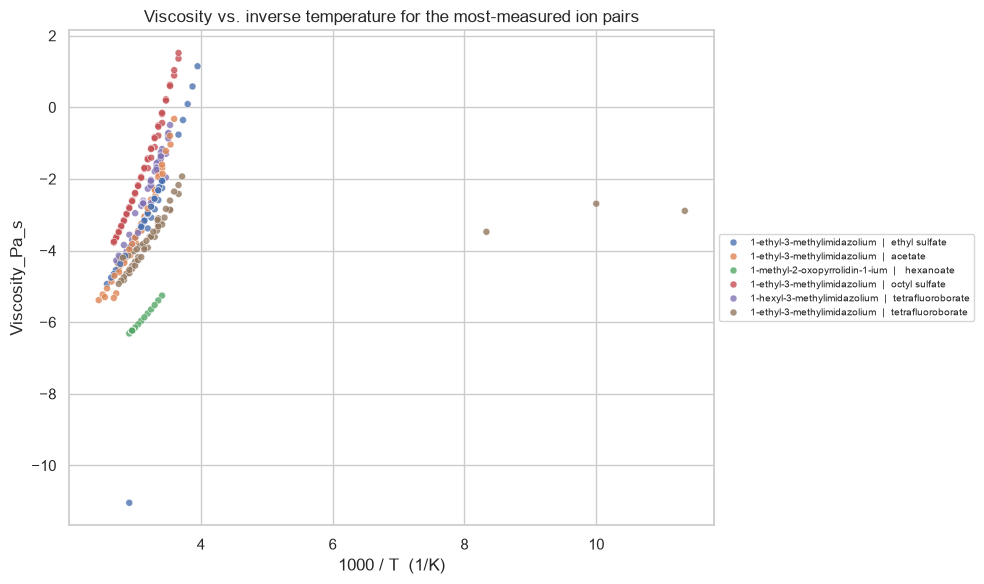

In [22]:
pair_label = train['Cation'] + '  |  ' + train['Anion']
top_pairs = pair_label.value_counts().head(6).index

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=train.loc[pair_label.isin(top_pairs), 'inv_T'] * 1000,
    y=train.loc[pair_label.isin(top_pairs), 'Viscosity_Pa_s'],
    hue=pair_label[pair_label.isin(top_pairs)],
    s=25, alpha=0.8,
)
plt.xlabel('1000 / T  (1/K)')
plt.ylabel('Viscosity_Pa_s')
plt.title('Viscosity vs. inverse temperature for the most-measured ion pairs')
plt.legend(fontsize=7, loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### 5.5 Effect of structure: cation alkyl chain length

Longer alkyl chains generally increase van der Waals interactions and therefore viscosity. The distribution of the target for each chain length shows whether the custom `Max_Alkyl_Length` feature captures this.

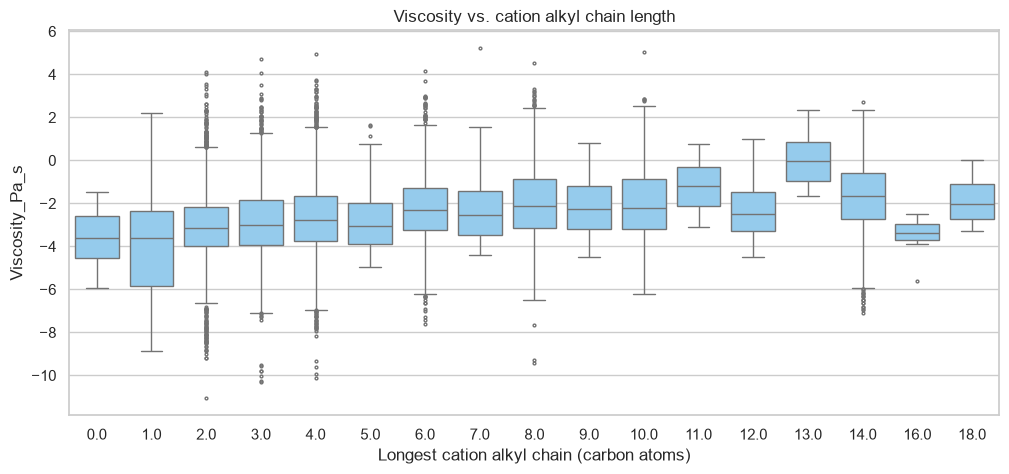

In [23]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=train, x='Cat_Max_Alkyl_Length', y='Viscosity_Pa_s', color='lightskyblue', fliersize=2)
plt.xlabel('Longest cation alkyl chain (carbon atoms)')
plt.ylabel('Viscosity_Pa_s')
plt.title('Viscosity vs. cation alkyl chain length')
plt.show()

---
## 6. Model Benchmarking with GroupKFold

The same ion pair appears at many temperatures, so a random split would leak near-duplicate rows between train and validation. Instead, **`GroupKFold`** is used with the group defined as `Cation_Anion`, so each ion pair lives entirely in one fold. This gives a more honest estimate of generalisation to unseen ion pairs.

Three regressors are compared on MSE, MAE and R².

In [24]:
# Build feature matrix, target and CV groups
data = train.drop(['Cat_sm', 'An_sm', 'Cation', 'Anion'], axis=1)
x = data.drop(['Viscosity_Pa_s'], axis=1)
y = data['Viscosity_Pa_s']
x = x.loc[:, ~x.columns.duplicated()]

groups = train['Cation'] + "_" + train['Anion']
gkf = GroupKFold(n_splits=5)

scoring = {
    'mse': 'neg_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2',
}

def report(scores):
    print("MSE:", -scores['test_mse'].mean())
    print("MAE:", -scores['test_mae'].mean())
    print("R2 :", scores['test_r2'].mean())

### 6.1 Random Forest

In [25]:
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=17,
    n_jobs=-1,
)

scores_rf = cross_validate(rf, x, y, cv=gkf, groups=groups, scoring=scoring, n_jobs=-1)
report(scores_rf)

MSE: 1.0740578355010721
MAE: 0.6265163996004346
R2 : 0.658833111144234


### 6.2 XGBoost

In [26]:
xg = XGBRegressor(
    n_estimators=180,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=17,
)

scores_xg = cross_validate(xg, x, y, cv=gkf, groups=groups, scoring=scoring)
report(scores_xg)

MSE: 1.073810717605345
MAE: 0.6314154256807301
R2 : 0.6595232173406288


### 6.3 CatBoost

In [27]:
cb = CatBoostRegressor(
    n_estimators=180,
    learning_rate=0.1,
    depth=6,
    subsample=0.8,
    rsm=0.8,
    random_state=17,
    verbose=0,
)

scores_cb = cross_validate(cb, x, y, cv=gkf, groups=groups, scoring=scoring)
report(scores_cb)

MSE: 0.9766357738072351
MAE: 0.6127357275649835
R2 : 0.6896450095024428


### 6.4 Out-of-fold predictions (CatBoost)

Scores summarise performance in one number; the out-of-fold predictions show *where* the model is wrong. Points should hug the diagonal, and residuals should be centred on zero without structure.

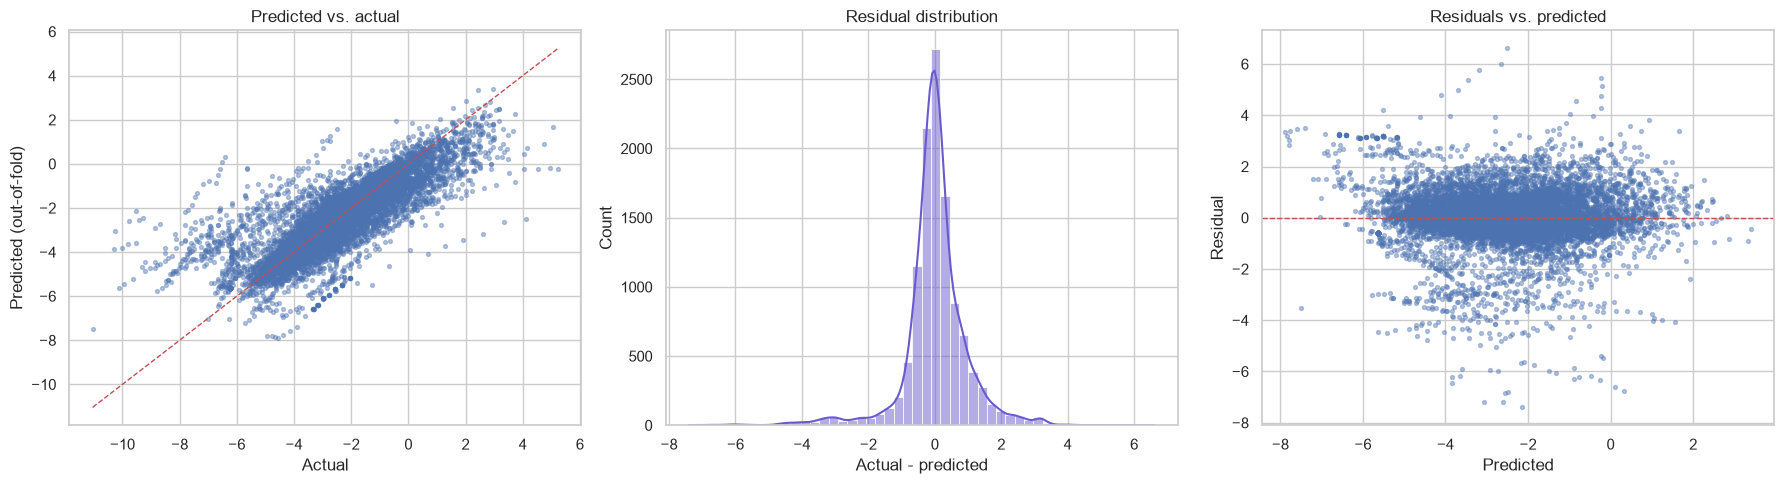

In [28]:
from sklearn.model_selection import cross_val_predict

oof_cb = cross_val_predict(cb, x, y, cv=gkf, groups=groups)
residuals = y - oof_cb

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y, oof_cb, s=8, alpha=0.4)
lims = [min(y.min(), oof_cb.min()), max(y.max(), oof_cb.max())]
axes[0].plot(lims, lims, 'r--', lw=1)
axes[0].set_xlabel('Actual'); axes[0].set_ylabel('Predicted (out-of-fold)')
axes[0].set_title('Predicted vs. actual')

sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color='slateblue')
axes[1].set_title('Residual distribution')
axes[1].set_xlabel('Actual - predicted')

axes[2].scatter(oof_cb, residuals, s=8, alpha=0.4)
axes[2].axhline(0, color='r', ls='--', lw=1)
axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('Residual')
axes[2].set_title('Residuals vs. predicted')

plt.tight_layout()
plt.show()

**CatBoost** scores best on all three metrics (MSE 0.977, MAE 0.613, R² 0.690), while Random Forest and XGBoost are close to each other. Since the models differ in how they build trees, blending them is expected to be more robust than relying on any single one.

---
## 7. Preparing the Test Set

The test data goes through exactly the same pipeline as the training data: SMILES merge → `1/T` → ion descriptors → interaction features.

In [29]:
test = test.merge(smiles, how='left', on=['Cation', 'Anion'])
test['inv_T'] = 1 / test['T']

test = add_ion_features(test)
test = add_interaction_features(test)
test.head()

,ID,Cation,Anion,T,Cat_sm,An_sm,inv_T,Cat_MW,Cat_NumHDonors,Cat_NumHAcceptors,...,An_Max_Alkyl_Length,Total_MW,total_F,hb_interact,charge_interaction,Tpsa_sum,MW_diff,invT_MW,invT_charge,invT_Tpsa
0,1,1-ethyl-1-(3-hydroxypropyl)piperidin-1-ium,bis(trifluoromethylsulfonyl)azanide,333.15,CC[N+]1(CCCO)CCCCC1,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F,0.003002,172.292,1.0,1.0,...,1.0,452.439,6.0,4.0,-1.0,102.61,107.855,1.358064,-0.003002,0.307999
1,2,hexyl(tributyl)phosphanium,bis(trifluoromethylsulfonyl)azanide,348.15,CCCCCC[P+](CCCC)(CCCC)CCCC,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F,0.002872,287.492,0.0,0.0,...,1.0,567.639,6.0,0.0,-1.0,82.38,7.345,1.630444,-0.002872,0.236622
2,3,triethyl(heptyl)phosphanium,4-nitro-1H-pyrazol-1-ide,323.15,CCCCCCC[P+](CC)(CC)CC,O=[N+]([O-])c1cn[n-]c1,0.003095,217.357,0.0,0.0,...,0.0,329.425,0.0,0.0,-1.0,70.13,105.289,1.019418,-0.003095,0.217020
3,4,1-butyl-1-methylpyrrolidinium,phenyltrifluoroborate,313.00,CCCC[N+]1(C)CCCC1,F[B-](F)(F)c1ccccc1,0.003195,142.266,0.0,0.0,...,0.0,287.178,3.0,0.0,-1.0,0.00,2.646,0.917502,-0.003195,0.000000
4,5,3-methyl-1-octylpyridin-1-ium,tetrafluoroborate,298.15,CCCCCCCC[n+]1cccc(C)c1,F[B-](F)(F)F,0.003354,206.353,0.0,0.0,...,0.0,293.157,4.0,0.0,-1.0,3.88,119.549,0.983253,-0.003354,0.013014


---
## 8. Final Predictions & Submission

Each model is refit on the full training set, then their predictions are blended with weights `CatBoost - 0.35 / XGBoost - 0.35 / Random Forest - 0.30`.

In [30]:
# Align test columns with the training feature matrix
tdata = test.drop(['Cat_sm', 'An_sm', 'Cation', 'Anion', 'ID'], axis=1)
tdata = tdata.loc[:, ~tdata.columns.duplicated()]

cb.fit(x, y)
rf.fit(x, y)
xg.fit(x, y)

predictions_cb = cb.predict(tdata)
predictions_rf = rf.predict(tdata)
predictions_xg = xg.predict(tdata)

In [31]:
predictions = 0.35 * predictions_cb + 0.35 * predictions_xg + 0.30 * predictions_rf

submission = pd.DataFrame({'ID': test['ID'], 'Viscosity_Pa_s': predictions})
submission.to_csv('submission.csv', index=False)
submission.head()

,ID,Viscosity_Pa_s
0,1,-3.454209
1,2,-3.404068
2,3,-2.631913
3,4,-1.957608
4,5,-1.114344


### 8.1 Model diagnostics

Which features do the final models rely on, and do the predictions on the test set look like the training target?

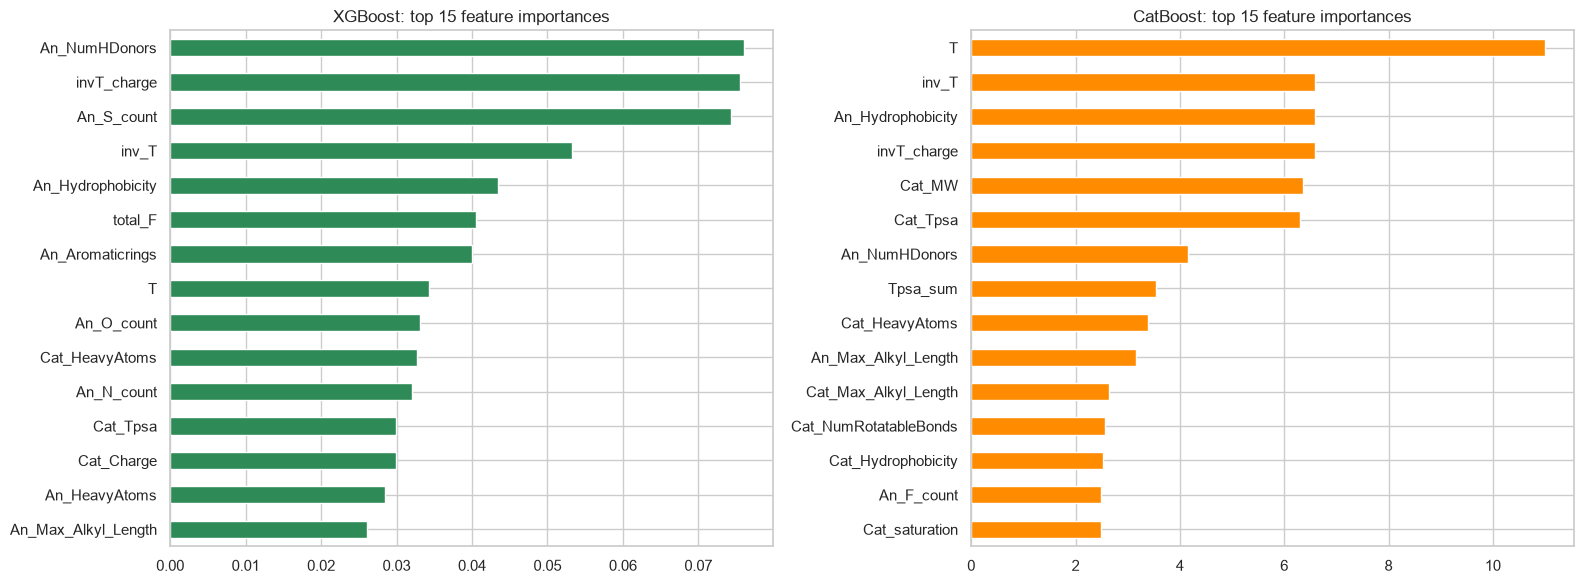

In [32]:
imp_xg = pd.Series(xg.feature_importances_, index=x.columns).sort_values(ascending=False).head(15)
imp_cb = pd.Series(cb.get_feature_importance(), index=x.columns).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
imp_xg[::-1].plot(kind='barh', ax=axes[0], color='seagreen')
axes[0].set_title('XGBoost: top 15 feature importances')
imp_cb[::-1].plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('CatBoost: top 15 feature importances')
plt.tight_layout()
plt.show()

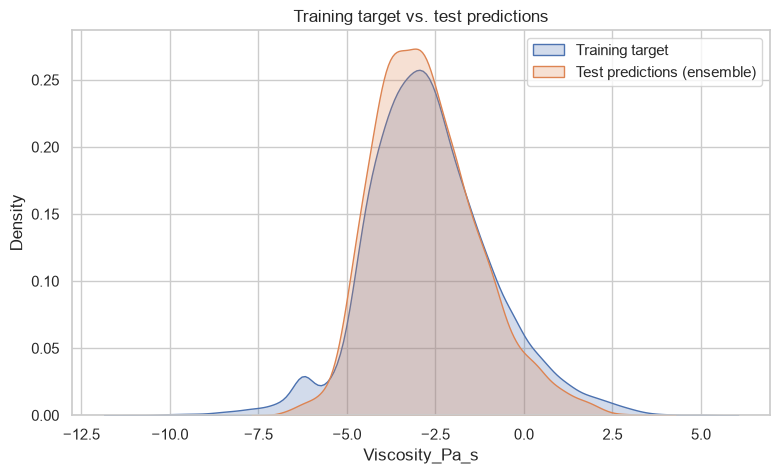

In [33]:
plt.figure(figsize=(9, 5))
sns.kdeplot(y, label='Training target', fill=True)
sns.kdeplot(predictions, label='Test predictions (ensemble)', fill=True)
plt.xlabel('Viscosity_Pa_s')
plt.title('Training target vs. test predictions')
plt.legend()
plt.show()